In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from datetime import datetime

In [3]:
## LOAD GENERAL STUFF
path_fsm=r'data\FSM_all.nc'
path_snow=r'data\snow_metrics.nc'
ds_terrain = xr.open_dataset(path_fsm,decode_times=True)
ds_snow = xr.open_dataset(path_snow,decode_times=True)

altitudes = ds_terrain['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_terrain['aspect'].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

#primary_mask = np.ones(len(altitudes))
primary_mask = (altitudes >= 1000) & (altitudes <= 2800)
primary_mask = np.where(primary_mask,1,np.nan)


for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]

    meb_peak = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF', season = curr_season).values.flatten() 
    fsm_peak = ds_snow["Peak_SWE"].sel(simulation='FSM_ALL', season = curr_season).values.flatten() 
    meb_scd = ds_snow["Snow_duration"].sel(simulation='MEB_DEF', season = curr_season).values.flatten() 
    fsm_scd = ds_snow["Snow_duration"].sel(simulation='FSM_ALL', season = curr_season).values.flatten() 
    
    primary_mask = np.where(meb_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(fsm_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(meb_scd > 2, primary_mask, np.nan)
    primary_mask = np.where(fsm_scd > 2, primary_mask, np.nan)


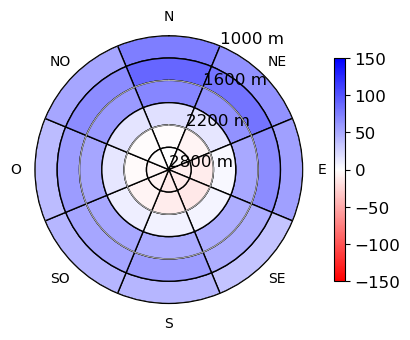

In [4]:
# COMPARISON MEB DEF - FSM ALL, ABSOLUTE
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MEB_ALL').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)



In [14]:
np.nanmean(variable)

np.float64(21.012964405108693)

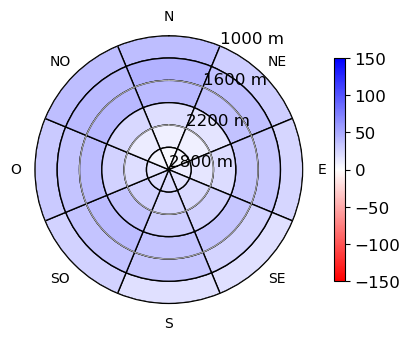

In [5]:
# COMPARISON MEB DEF - FSM ALL, ABSOLUTE
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='MEB_ALL').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)



In [6]:
np.nanmean(variable)

np.float64(24.504908799977677)

In [18]:
25/46

0.5434782608695652

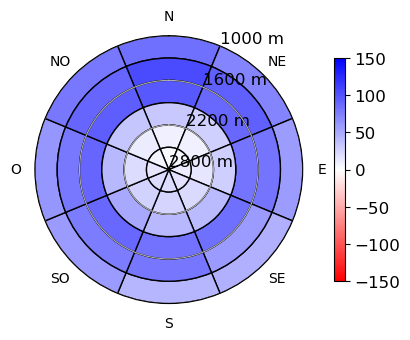

In [7]:
# COMPARISON MEB DEF - FSM ALL, ABSOLUTE
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='MXT_ALL').mean(dim="season", skipna=True).values.flatten() 

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)



In [6]:
np.mean(variable)

np.float64(43.40786142906534)

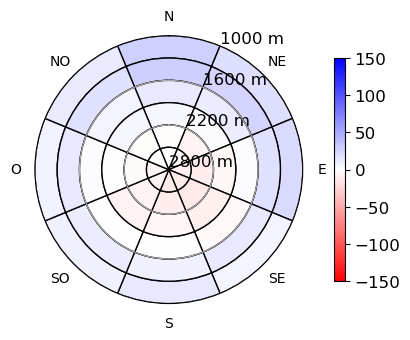

In [19]:
# COMPARISON MEB DEF - FSM ALL, ABSOLUTE
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MXT_ALL').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)



In [22]:
np.nanmean(variable)/46

np.float64(0.015813007605525148)

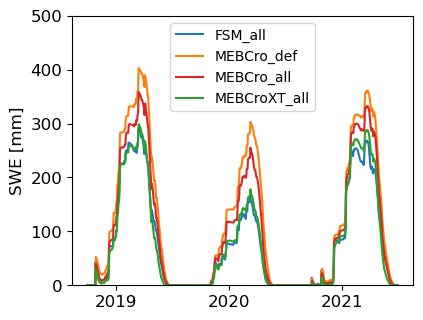

In [26]:
# TIME SERIES ANALYSES
# TIME SERIES ANALYSES
path_fsm=r'data\FSM_all_corr.nc'
path_meb1=r'data\MEBCro_all.nc'
path_meb2=r'data\MEBCroXT_all.nc'
path_meb3=r'data\MEBCro_def.nc'
ds_fsm = xr.open_dataset(path_fsm,decode_times=True)
ds_meb1 = xr.open_dataset(path_meb1,decode_times=True)
ds_meb2 = xr.open_dataset(path_meb2,decode_times=True)
ds_meb3 = xr.open_dataset(path_meb3,decode_times=True)

start_time = datetime(2018, 10, 2, 6, 0)
end_time = datetime(2021, 6, 30, 6, 0)
# 
#  time series for specific elevation band - FSM-ALL vs. MEB-DEF -- FIGURE 3
mask = ((ds_fsm['dem'] >= 1300) & (ds_fsm['dem'] <= 1900))
masked_data_fsm = ds_fsm["swet_all_corr"].where(mask).mean(dim=("yy", "xx"), skipna=True)
masked_data_meb1 = ds_meb1["swet_all"].where(mask).mean(dim=("yy", "xx"), skipna=True)
masked_data_meb2 = ds_meb2["swet_all"].where(mask).mean(dim=("yy", "xx"), skipna=True)
masked_data_meb3 = ds_meb3["swet_all"].where(mask).mean(dim=("yy", "xx"), skipna=True)





# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(4.4, 3.5), sharex=True)

ax.plot(ds_fsm["time"].sel(time=slice(start_time, end_time)), masked_data_fsm.sel(time=slice(start_time, end_time)), color='tab:blue', linewidth=1.5, label='FSM_all')
ax.plot(ds_meb3["time"].sel(time=slice(start_time, end_time)), masked_data_meb3.sel(time=slice(start_time, end_time)), color='tab:orange', linewidth=1.5, label='MEBCro_def')
ax.plot(ds_meb1["time"].sel(time=slice(start_time, end_time)), masked_data_meb1.sel(time=slice(start_time, end_time)), color='tab:red', linewidth=1.5, label='MEBCro_all')
ax.plot(ds_meb2["time"].sel(time=slice(start_time, end_time)), masked_data_meb2.sel(time=slice(start_time, end_time)), color='tab:green', linewidth=1.5, label='MEBCroXT_all')


ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(0,500)
ax.set_ylabel('SWE [mm]', fontsize=12)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)

#fig.text(0.04, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


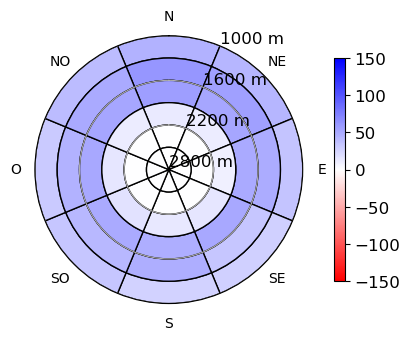

In [8]:
# COMPARISON MEB DEF - FSM ALL, ABSOLUTE
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MEB_ALL').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='MXT_ALL').mean(dim="season", skipna=True).values.flatten() 

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)